# Ejercicio 4: Descenso de Gradiente (Selección Heurística)
**Matemáticas para Inteligencia Artificial**

Función objetivo en 4 variables:
$$f(x_1, x_2, x_3, x_4) = x_1^4 + 2x_2^4 + 3x_3^4 + 4x_4^4 - 4x_1 - 8x_2 - 12x_3 - 16x_4 + (x_1 - x_2)^2 + (x_2 - x_3)^2 + (x_3 - x_4)^2$$

Derivadas parciales (gradiente $\nabla f(x)$):
* $\frac{\partial f}{\partial x_1} = 4x_1^3 - 4 + 2(x_1 - x_2)$
* $\frac{\partial f}{\partial x_2} = 8x_2^3 - 8 - 2(x_1 - x_2) + 2(x_2 - x_3)$
* $\frac{\partial f}{\partial x_3} = 12x_3^3 - 12 - 2(x_2 - x_3) + 2(x_3 - x_4)$
* $\frac{\partial f}{\partial x_4} = 16x_4^3 - 16 - 2(x_3 - x_4)$

En este notebook realizaremos:
1. Implementación de $f(x)$, su gradiente $\nabla f(x)$ y el algoritmo de descenso de gradiente.
2. Pruebas heurísticas con varios valores de $\gamma$ y $x_0$ para observar divergencia, oscilación y velocidad de convergencia.
3. Ejecución final hasta que $\|\nabla f(x_i)\| < 10^{-6}$ reportando $x^*$, $f(x^*)$, el gradiente final y el número de iteraciones.
4. Gráfica de $f(x_i)$ contra $i$.


## 1. Importación de librerías, función objetivo y gradiente


In [1]:
import numpy as np              # Para operaciones con vectores y normas
import pandas as pd             # Para resumir las pruebas heurísticas en tablas
import matplotlib.pyplot as plt # Para graficar la convergencia de f(x_i)

# Inciso 1: Definición de la función objetivo f(x1, x2, x3, x4)
def f(x):
    x1, x2, x3, x4 = x[0], x[1], x[2], x[3]
    return (x1**4 + 2*(x2**4) + 3*(x3**4) + 4*(x4**4)
            - 4*x1 - 8*x2 - 12*x3 - 16*x4
            + (x1 - x2)**2 + (x2 - x3)**2 + (x3 - x4)**2)

# Definición del gradiente de f(x) (vector con las 4 derivadas parciales)
def gradiente(x):
    x1, x2, x3, x4 = x[0], x[1], x[2], x[3]
    df_dx1 = 4*(x1**3) - 4 + 2*(x1 - x2)
    df_dx2 = 8*(x2**3) - 8 - 2*(x1 - x2) + 2*(x2 - x3)
    df_dx3 = 12*(x3**3) - 12 - 2*(x2 - x3) + 2*(x3 - x4)
    df_dx4 = 16*(x4**3) - 16 - 2*(x3 - x4)
    return np.array([df_dx1, df_dx2, df_dx3, df_dx4], dtype=float)

# Función reutilizable de Descenso de Gradiente
def descenso_gradiente(x0, gamma, tolerancia=1e-6, max_iter=2000):
    x = np.array(x0, dtype=float)
    historial = []
    estado = "No convergió (límite de iteraciones)"

    for i in range(max_iter):
        grad = gradiente(x)
        norma_grad = np.linalg.norm(grad)
        valor_f = f(x)

        # Detección de divergencia (valores infinitos, NaN o demasiado grandes)
        if np.isnan(norma_grad) or np.isinf(norma_grad) or norma_grad > 1e12:
            estado = "Diverge"
            break

        historial.append({
            "i": i,
            "x": x.copy(),
            "grad": grad.copy(),
            "||grad||": norma_grad,
            "f(x_i)": valor_f
        })

        # Criterio de paro: ||gradiente|| < tolerancia
        if norma_grad < tolerancia:
            estado = "Converge"
            break

        # Actualización del descenso de gradiente: x_{i+1} = x_i - gamma * gradiente
        x = x - gamma * grad

    return pd.DataFrame(historial), estado

## 2. Selección heurística de $\gamma$ y $x_0$


In [2]:
# Inciso 2: Probamos varias tasas de aprendizaje (gamma) partiendo desde x0 = [0, 0, 0, 0]
x0_base = [0.0, 0.0, 0.0, 0.0]
gammas_prueba = [0.1, 0.05, 0.04, 0.03, 0.02, 0.01, 0.001]

resultados_gamma = []
for g in gammas_prueba:
    df_prueba, estado = descenso_gradiente(x0_base, gamma=g, tolerancia=1e-6, max_iter=2000)
    ultima = df_prueba.iloc[-1]
    
    # Si no convergió en el límite pero no explotó, verificamos si oscilaba
    if estado == "No convergió (límite de iteraciones)":
        estado = "Oscila (no converge)"
        
    resultados_gamma.append({
        "gamma": g,
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "f(x) final": round(ultima["f(x_i)"], 6),
        "||grad|| final": f"{ultima['||grad||']:.2e}"
    })

print("Pruebas con diferentes valores de gamma (usando x0 = [0, 0, 0, 0]):")
tabla_gammas = pd.DataFrame(resultados_gamma)
tabla_gammas

Pruebas con diferentes valores de gamma (usando x0 = [0, 0, 0, 0]):


,gamma,Estado,Iteraciones,f(x) final,||grad|| final
0,0.100,Diverge,3,6.581137e+07,4.13e+06
1,0.050,Oscila (no converge),1999,-2.599104e+01,1.66e+01
2,0.040,Oscila (no converge),1999,-2.984840e+01,3.72e+00
3,0.030,Converge,36,-3.000000e+01,6.55e-07
4,0.020,Converge,58,-3.000000e+01,7.73e-07
5,0.010,Converge,123,-3.000000e+01,9.54e-07
6,0.001,Converge,1299,-3.000000e+01,9.87e-07


In [3]:
# Ahora probamos distintos puntos iniciales x0 usando la mejor tasa encontrada (gamma = 0.03)
puntos_iniciales = [
    [0.0, 0.0, 0.0, 0.0],
    [-1.0, -1.0, -1.0, -1.0],
    [2.0, 2.0, 2.0, 2.0],
    [3.0, -2.0, 4.0, -1.0]
]

resultados_x0 = []
for x0_p in puntos_iniciales:
    df_prueba, estado = descenso_gradiente(x0_p, gamma=0.03, tolerancia=1e-6, max_iter=2000)
    ultima = df_prueba.iloc[-1]
    resultados_x0.append({
        "x0": str(x0_p),
        "Estado": estado,
        "Iteraciones": int(ultima["i"]),
        "x* encontrado": np.round(ultima["x"], 4) if estado == "Converge" else "N/A",
        "f(x*)": round(ultima["f(x_i)"], 6) if estado == "Converge" else "N/A"
    })

print("Pruebas con diferentes puntos iniciales x0 (usando gamma = 0.03):")
tabla_x0 = pd.DataFrame(resultados_x0)
tabla_x0

Pruebas con diferentes puntos iniciales x0 (usando gamma = 0.03):


,x0,Estado,Iteraciones,x* encontrado,f(x*)
0,"[0.0, 0.0, 0.0, 0.0]",Converge,36,"[1.0, 1.0, 1.0, 1.0]",-30.0
1,"[-1.0, -1.0, -1.0, -1.0]",Converge,41,"[1.0, 1.0, 1.0, 1.0]",-30.0
2,"[2.0, 2.0, 2.0, 2.0]",Converge,30,"[1.0, 1.0, 1.0, 1.0]",-30.0
3,"[3.0, -2.0, 4.0, -1.0]",Diverge,2,N/A,N/A


### Conclusión de la selección heurística
* **Elección de $\gamma = 0.03$:**
  * Con $\gamma = 0.1$ el algoritmo **diverge** en pocas iteraciones porque el término $x^3$ del gradiente hace que el paso crezca sin control.
  * Con $\gamma = 0.05$ y $\gamma = 0.04$ el método **oscila** cerca del mínimo y no logra bajar la norma del gradiente por debajo de $10^{-6}$.
  * Con $\gamma = 0.001$ converge, pero **demasiado lento** (1299 iteraciones).
  * Con $\gamma = 0.03$ se obtiene la convergencia más rápida y estable (**36 iteraciones**).
* **Elección de $x_0 = (0, 0, 0, 0)$:**
  * Al probar varios puntos iniciales moderados ($[0,0,0,0]$, $[-1,-1,-1,-1]$, $[2,2,2,2]$), todos convergen al mismo mínimo $x^* = (1, 1, 1, 1)$.
  * Puntos muy alejados como $[3, -2, 4, -1]$ hacen que el gradiente cúbico sea enorme y diverjan con $\gamma = 0.03$. Por ello elegimos **$x_0 = [0, 0, 0, 0]$** como punto inicial neutro y seguro.
* **Límite de iteraciones:** Se fijó `max_iter = 2000` como margen suficiente para detectar convergencia lenta sin caer en bucles infinitos.


## 3. Ejecución final y reporte del mínimo encontrado


In [4]:
# Inciso 3: Ejecutamos el método con los parámetros elegidos heurísticamente
x0_elegido = [0.0, 0.0, 0.0, 0.0]
gamma_elegido = 0.03
tolerancia = 1e-6

tabla, estado = descenso_gradiente(x0_elegido, gamma=gamma_elegido, tolerancia=tolerancia, max_iter=2000)

# Extraemos la última iteración (punto de convergencia)
final = tabla.iloc[-1]

print("=== RESULTADO FINAL (EJERCICIO 4) ===")
print(f"Estado:               {estado}")
print(f"Parámetros elegidos:  gamma = {gamma_elegido}, x0 = {x0_elegido}")
print(f"Iteraciones totales:  {int(final['i'])}")
print(f"Mínimo encontrado x*: {np.round(final['x'], 6)}")
print(f"Valor mínimo f(x*):   {final['f(x_i)']:.6f}")
print(f"Gradiente final:      {np.array2string(final['grad'], formatter={'float_kind': lambda v: f'{v:.2e}'})}")
print(f"Norma del gradiente:  {final['||grad||']:.2e}")

=== RESULTADO FINAL (EJERCICIO 4) ===
Estado:               Converge
Parámetros elegidos:  gamma = 0.03, x0 = [0.0, 0.0, 0.0, 0.0]
Iteraciones totales:  36
Mínimo encontrado x*: [1. 1. 1. 1.]
Valor mínimo f(x*):   -30.000000
Gradiente final:      [-6.49e-07 -9.19e-08 -6.96e-09 -6.99e-10]
Norma del gradiente:  6.55e-07


## 4. Gráfica de $f(x_i)$ contra $i$


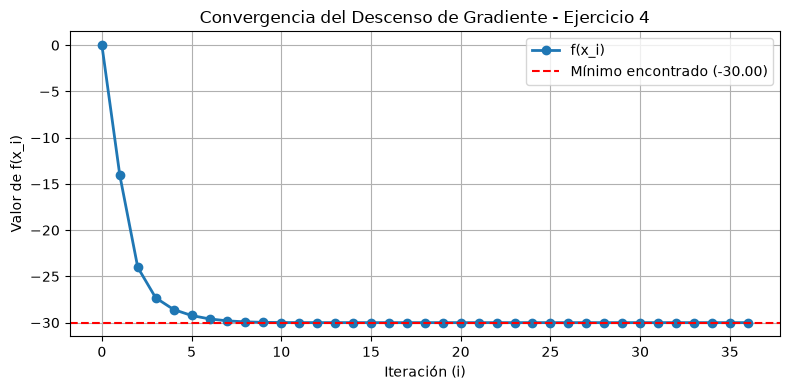

In [5]:
# Inciso 4: Graficamos el descenso del valor de la función en cada iteración
plt.figure(figsize=(8, 4))
plt.plot(tabla["i"], tabla["f(x_i)"], marker="o", linewidth=2, label="f(x_i)")
plt.axhline(final["f(x_i)"], color="red", linestyle="--", label=f"Mínimo encontrado ({final['f(x_i)']:.2f})")

plt.title("Convergencia del Descenso de Gradiente - Ejercicio 4")
plt.xlabel("Iteración (i)")
plt.ylabel("Valor de f(x_i)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()